# NetSentry
## Network Intrusion Detection Using Machine Learning

### Domain
Cybersecurity

### Project Type
Supervised Machine Learning – Classification

### Project Overview
Network Intrusion Detection is a cybersecurity application that identifies suspicious or malicious activities in network traffic. This project aims to develop a Machine Learning model that analyses network traffic features and classifies network activities as normal or malicious.

### Objectives
1. Understand network intrusion detection.
2. Investigate and analyse the CIC-IDS2017 dataset.
3. Perform data cleaning and preprocessing.
4. Conduct Exploratory Data Analysis (EDA).
5. Implement three Machine Learning algorithms.
6. Evaluate and compare model performance.
7. Select the best-performing model.
8. Analyse the limitations and future scope of the project.

### Algorithms
- Logistic Regression
- Decision Tree
- Random Forest

### Tools and Technologies
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

## Problem Statement

To develop a Machine Learning model to detect and classify normal and malicious network traffic for identifying potential cyberattacks.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/NetSentry_Dataset/MachineLearningCVE"

files = os.listdir(dataset_path)

print("Total CSV Files:", len(files))

for file in files:
    print(file)

Total CSV Files: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import glob
import os

csv_files = glob.glob(dataset_path + "/*.csv")

dataframes = []

for file in csv_files:
    df = pd.read_csv(file, low_memory=False)
    dataframes.append(df)

df = pd.concat(dataframes, ignore_index=True)

print("Dataset Loaded Successfully!")
print("Shape:", df.shape)

Dataset Loaded Successfully!
Shape: (2830743, 79)


In [ ]:
# First 5 rows
display(df.head())

# Column names
print("Columns:")
print(df.columns.tolist())

# Dataset information
df.info()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


Columns:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count', ' 

In [ ]:
# Check missing values

missing_values = df.isnull().sum()

print("Total Missing Values:", missing_values.sum())

print("\nColumns with Missing Values:")

print(missing_values[missing_values > 0])


Total Missing Values: 1358

Columns with Missing Values:
Flow Bytes/s    1358
dtype: int64


In [ ]:
# Count duplicate rows

duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

Total Duplicate Rows: 308381


In [ ]:
print(df.columns.tolist())

[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count', ' URG Flag 

In [ ]:
df.columns = df.columns.str.strip()

print("Column names cleaned!")
print(df.columns.tolist())

Column names cleaned!
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag C

In [ ]:
print("Unique Labels:")
print(df['Label'].unique())

print("\nLabel Distribution:")
print(df['Label'].value_counts())

Unique Labels:
['BENIGN' 'DDoS' 'PortScan' 'Bot' 'Infiltration'
 'Web Attack � Brute Force' 'Web Attack � XSS'
 'Web Attack � Sql Injection' 'FTP-Patator' 'SSH-Patator' 'DoS slowloris'
 'DoS Slowhttptest' 'DoS Hulk' 'DoS GoldenEye' 'Heartbleed']

Label Distribution:
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


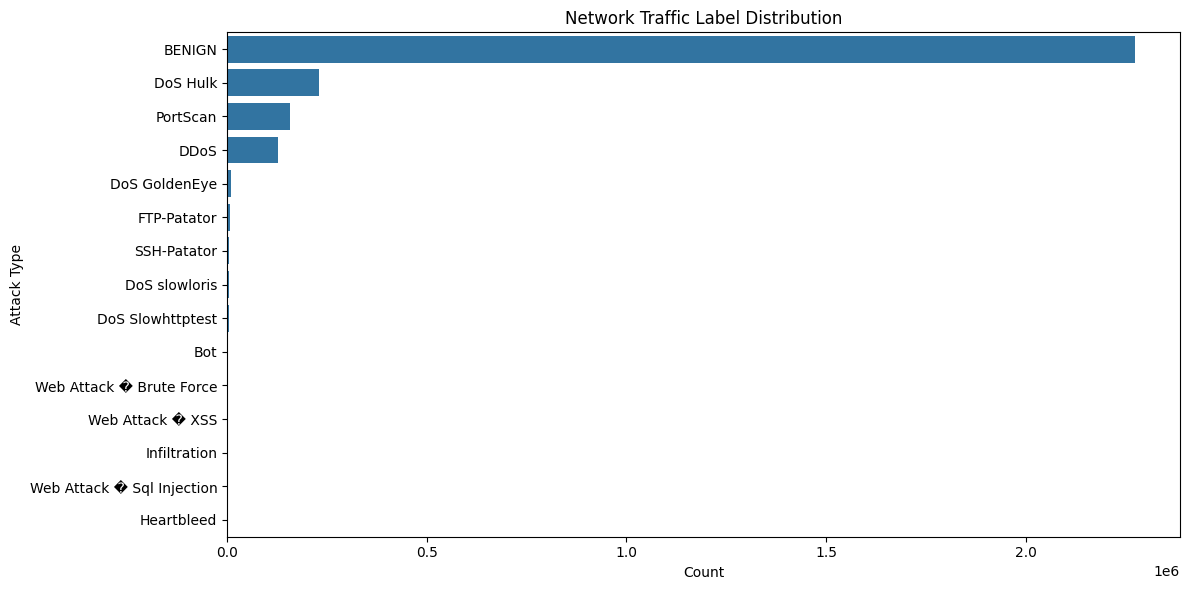

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='Label',
    order=df['Label'].value_counts().index
)

plt.title("Network Traffic Label Distribution")
plt.xlabel("Count")
plt.ylabel("Attack Type")
plt.tight_layout()
plt.show()


In [7]:
# GRAPH 4: Flow Duration Distribution

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 5))

sample_data = df.sample(
    n=min(20000, len(df)),
    random_state=42
)

sns.histplot(
    data=sample_data,
    x='Flow Duration',
    bins=50,
    kde=True
)

plt.xscale('symlog')
plt.title('Distribution of Network Flow Duration')
plt.xlabel('Flow Duration')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

<Figure size 1000x500 with 0 Axes>

In [ ]:
# GRAPH 5: Feature Correlation Heatmap

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
numeric_data = df.select_dtypes(include=np.number)

top_features = (
    numeric_data.var()
    .nlargest(12)
    .index
)

correlation = numeric_data[top_features].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Network Features')
plt.tight_layout()
plt.show()

NameError: name 'df_cleaned' is not defined

In [ ]:
# Check missing values

missing_values = df.isnull().sum()

print("Total Missing Values:")
print(missing_values.sum())

print("\nColumns with Missing Values:")
print(missing_values[missing_values > 0])

In [ ]:
import numpy as np

# Check infinite values

print("Total Infinite Values:",
      np.isinf(df.select_dtypes(include=np.number)).sum().sum())

In [ ]:
# Replace infinite values with NaN

df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Infinite values replaced successfully!")

In [ ]:
# Remove rows containing missing values

df.dropna(inplace=True)

print("Missing values removed!")
print("New Dataset Shape:", df.shape)
print("Remaining Missing Values:", df.isnull().sum().sum())

In [ ]:
print("Total Infinite Values:",
      np.isinf(df.select_dtypes(include=np.number)).sum().sum())

print("Total Missing Values:", df.isnull().sum().sum())

In [ ]:
# Check duplicate rows

duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

In [ ]:
# Remove duplicate rows

df.drop_duplicates(inplace=True)

print("Duplicate rows removed successfully!")

print("New Dataset Shape:", df.shape)

print("Remaining Duplicate Rows:", df.duplicated().sum())

In [ ]:
# Separate features and target

X = df.drop('Label', axis=1)

y = df['Label']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Classes:")
print(y.unique())

In [ ]:
# Check data types

print("Numerical Columns:")
print(X.select_dtypes(include=['number']).shape[1])

print("\nCategorical Columns:")
print(X.select_dtypes(include=['object']).shape[1])

print("\nCategorical Column Names:")
print(X.select_dtypes(include=['object']).columns.tolist())

In [ ]:
# Statistical summary of features

print(X.describe().T)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("Feature Scaling Completed!")
print("New Shape:", X_scaled.shape)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=30,
    max_depth=15,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:

import os
import glob
import pandas as pd
import numpy as np

dataset_path = "/content/drive/MyDrive/NetSentry_Dataset/MachineLearningCVE"

csv_files = glob.glob(dataset_path + "/*.csv")

dataframes = []

for file in csv_files:
    temp_df = pd.read_csv(file, low_memory=False)
    dataframes.append(temp_df)

df = pd.concat(dataframes, ignore_index=True)

print("Dataset Loaded:", df.shape)


In [ ]:
# Clean column names

df.columns = df.columns.str.replace('\ufeff', '', regex=False).str.strip()

print("Column names cleaned!")
print(df.columns.tolist())

In [ ]:
# Find target column

label_col = [col for col in df.columns if col.lower() == 'label']

print("Label Column Found:", label_col)

In [ ]:
# Check target class distribution

print("Target Classes:")
print(df['Label'].value_counts())

# Check unique labels
print("\nUnique Labels:")
print(df['Label'].nunique())

In [ ]:
# Check missing values

print("Total Missing Values:")
print(df.isnull().sum().sum())

# Replace infinite values

import numpy as np

df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove missing values

df.dropna(inplace=True)

print("\nMissing Values Removed!")
print("New Dataset Shape:", df.shape)

print("Remaining Missing Values:", df.isnull().sum().sum())

In [ ]:
# Check duplicate rows

duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

In [ ]:
# Replace infinite values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove missing values
df.dropna(inplace=True)

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Check final dataset
print("Final Dataset Shape:", df.shape)
print("Remaining Missing Values:", df.isnull().sum().sum())
print("Remaining Duplicate Rows:", df.duplicated().sum())

In [ ]:
# Separate features and target

X = df.drop('Label', axis=1)

y = df['Label']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Classes:")
print(y.unique())

In [ ]:
# Check data types

print("Numerical Columns:")
print(X.select_dtypes(include=['number']).shape[1])

print("\nCategorical Columns:")
print(X.select_dtypes(include=['object']).shape[1])

print("\nCategorical Column Names:")
print(X.select_dtypes(include=['object']).columns.tolist())

In [ ]:
# Statistical summary of features

print(X.describe().T)

In [ ]:
# Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

In [ ]:
# Create a smaller sample for training

X_sample = X_train.sample(
    n=200000,
    random_state=42
)

y_sample = y_train.loc[X_sample.index]

print("Sample Features:", X_sample.shape)
print("Sample Target:", y_sample.shape)

In [ ]:
# Train Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=30,
    max_depth=15,
    min_samples_split=5,
    random_state=42,
    n_jobs=1
)

rf_model.fit(X_sample, y_sample)

print("Random Forest Model Trained Successfully!")


In [ ]:
# Make predictions

y_pred = rf_model.predict(X_test)

print("Predictions Completed Successfully!")
print("Prediction Shape:", y_pred.shape)

In [ ]:
# Import evaluation metrics

from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100)

# Classification Report

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

In [ ]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)

plt.figure(figsize=(14, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)

disp.plot(cmap='Blues', xticks_rotation=90)

plt.title("Random Forest Confusion Matrix")
plt.show()

In [ ]:
# Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_sample.columns
)

feature_importance = feature_importance.sort_values(ascending=False)

plt.figure(figsize=(12, 8))

feature_importance.head(15).plot(kind='bar')

plt.title("Top 15 Important Features")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=90)

plt.show()

In [ ]:
# Save Random Forest Model

import joblib

joblib.dump(rf_model, "NetSentry_RandomForest_Model.pkl")

print("Model Saved Successfully!")

In [ ]:
from google.colab import files

files.download("NetSentry_RandomForest_Model.pkl")

In [ ]:
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("X_sample:", X_sample.shape)
print("Model:", type(rf_model))


In [ ]:

# NetSentry - Network Intrusion Prediction System

def predict_intrusion(input_data):

    # Check input columns
    missing_columns = set(X_sample.columns) - set(input_data.columns)

    if missing_columns:
        raise ValueError(f"Missing columns: {missing_columns}")

    # Arrange columns in correct order
    input_data = input_data[X_sample.columns]

    # Make prediction
    prediction = rf_model.predict(input_data)

    # Display result
    print("Network Traffic Prediction:", prediction[0])

    if prediction[0] == "BENIGN":
        print("Status: Normal Traffic")
    else:
        print("Status: ATTACK DETECTED!")

    return prediction[0]


print("NetSentry Prediction System Ready!")


In [ ]:
# Test with unseen network traffic

new_traffic = X_test.iloc[[0]]

result = predict_intrusion(new_traffic)

print("Actual Label:", y_test.iloc[0])
print("Predicted Label:", result)

In [ ]:
# Test Multiple Network Traffic Samples

for i in range(10):
    new_traffic = X_test.iloc[[i]]

    actual = y_test.iloc[i]
    predicted = predict_intrusion(new_traffic)

    print("Sample:", i+1)
    print("Actual:", actual)
    print("Predicted:", predicted)
    print("-" * 40)

In [8]:
print(df.shape)

NameError: name 'df' is not defined